# Notebook 1: EDA & Preprocessing
## Low-Resource NLP for Indian Languages — Hinglish Sentiment Classifier

**Dataset:** Hinglish dataset (Mendeley)  
**Columns:** `text`, `sentiment` (neutral / positive / negative), `label` (1 / 2 / 0)  
**Goal:** Explore the data, clean it, and save ready-to-use artefacts for downstream notebooks.

## 0. Install & Import

In [ ]:
# ── Install dependencies (run once) ──────────────────────────────────────────
# !pip install pandas numpy matplotlib seaborn wordcloud langdetect emoji nltk scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
import string
import warnings
warnings.filterwarnings('ignore')

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
print('All imports successful ✓')

All imports successful ✓


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load Dataset

In [ ]:
# ── Load ──────────────────────────────────────────────────────────────────────
DATA_PATH = '/content/drive/MyDrive/data/Hinglish_balanced_v3.csv'   # adjust path if needed

df = pd.read_csv(DATA_PATH)

# Drop the unnamed index column if present
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head()

Shape: (5706, 3)
Columns: ['text', 'sentiment', 'label']


,text,sentiment,label
0,"module , ek program hoti hai , jismen ya to so...",neutral,1
1,aur hamne aume samood ke pas unke bhaee saleh ...,positive,2
2,"aur jab unhen yad dilaya jata hai , to ve yad ...",neutral,1
3,tumhen २०११ ka ted prize mil gaya hai\n,positive,2
4,unhonne bad science karne ke lie ye delhi univ...,neutral,1


## 2. Basic EDA

In [ ]:
# ── Data types & missing values ───────────────────────────────────────────────
print('=== dtypes ===')
print(df.dtypes)
print('\n=== Missing values ===')
print(df.isnull().sum())
print('\n=== Duplicated rows ===')
print(df.duplicated().sum())

=== dtypes ===
text         object
sentiment    object
label         int64
dtype: object

=== Missing values ===
text         0
sentiment    0
label        0
dtype: int64

=== Duplicated rows ===
0


In [ ]:
df = df.drop_duplicates(subset=['text'])
print(df['sentiment'].value_counts())

sentiment
positive    1998
neutral     1891
negative    1817
Name: count, dtype: int64


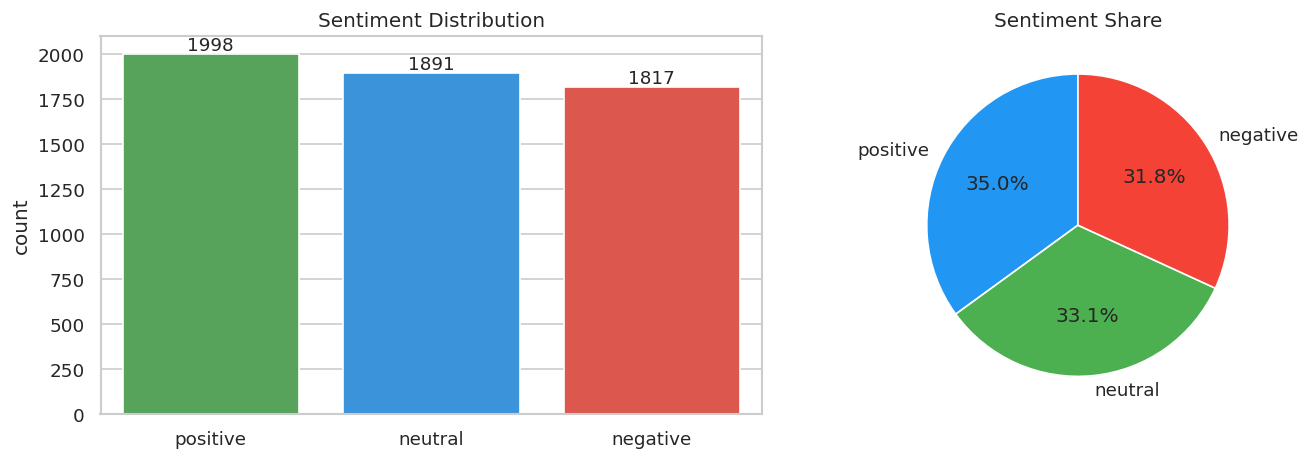

sentiment
positive    1998
neutral     1891
negative    1817
Name: count, dtype: int64


In [ ]:
# ── Label distribution ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Sentiment counts
order = ['positive', 'neutral', 'negative']
palette = {'positive': '#4caf50', 'neutral': '#2196f3', 'negative': '#f44336'}
sns.countplot(data=df, x='sentiment', order=order, palette=palette, ax=axes[0])
axes[0].set_title('Sentiment Distribution')
axes[0].set_xlabel('')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=11)

# Pie chart
counts = df['sentiment'].value_counts()
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%',
            colors=['#2196f3', '#4caf50', '#f44336'], startangle=90)
axes[1].set_title('Sentiment Share')

plt.tight_layout()
plt.savefig('label_distribution.png')
plt.show()
print(df['sentiment'].value_counts())

       text_length  word_count
count      5706.00     5706.00
mean         80.05       14.34
std          66.44       12.20
min          17.00        3.00
25%          44.00        8.00
50%          59.00       11.00
75%          88.00       15.00
max         853.00      157.00


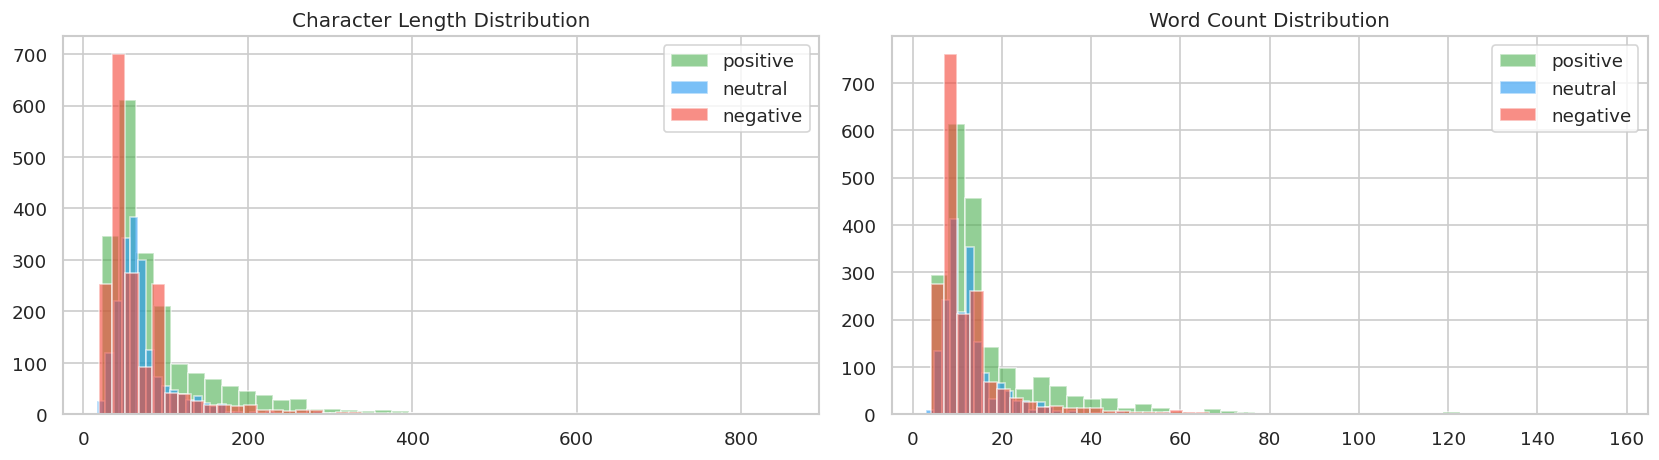

In [ ]:
# ── Text length analysis ──────────────────────────────────────────────────────
df['text_length']     = df['text'].str.len()
df['word_count']      = df['text'].str.split().str.len()

print(df[['text_length', 'word_count']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes,
                           ['text_length', 'word_count'],
                           ['Character Length Distribution', 'Word Count Distribution']):
    for sentiment, color in palette.items():
        subset = df[df['sentiment'] == sentiment][col]
        ax.hist(subset, bins=40, alpha=0.6, label=sentiment, color=color)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig('text_length_distribution.png')
plt.show()

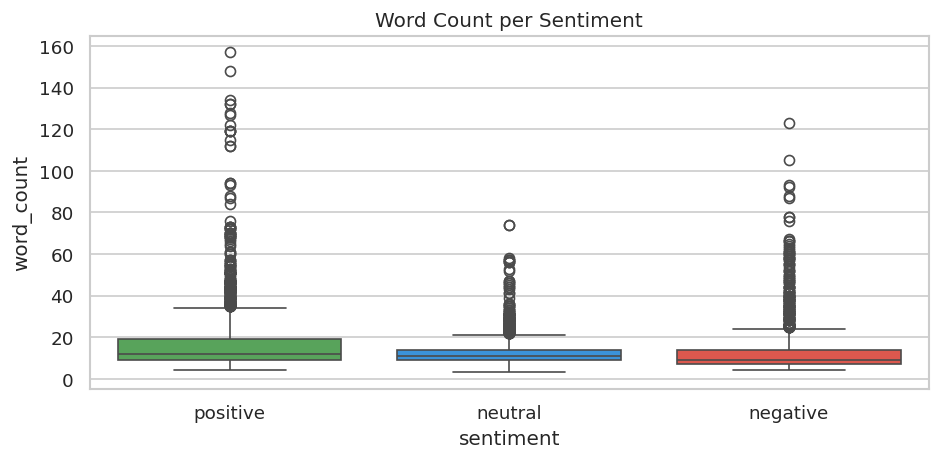

In [ ]:
# ── Box plot: word count per sentiment ───────────────────────────────────────
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='sentiment', y='word_count', order=order, palette=palette)
plt.title('Word Count per Sentiment')
plt.tight_layout()
plt.savefig('boxplot_word_count.png')
plt.show()

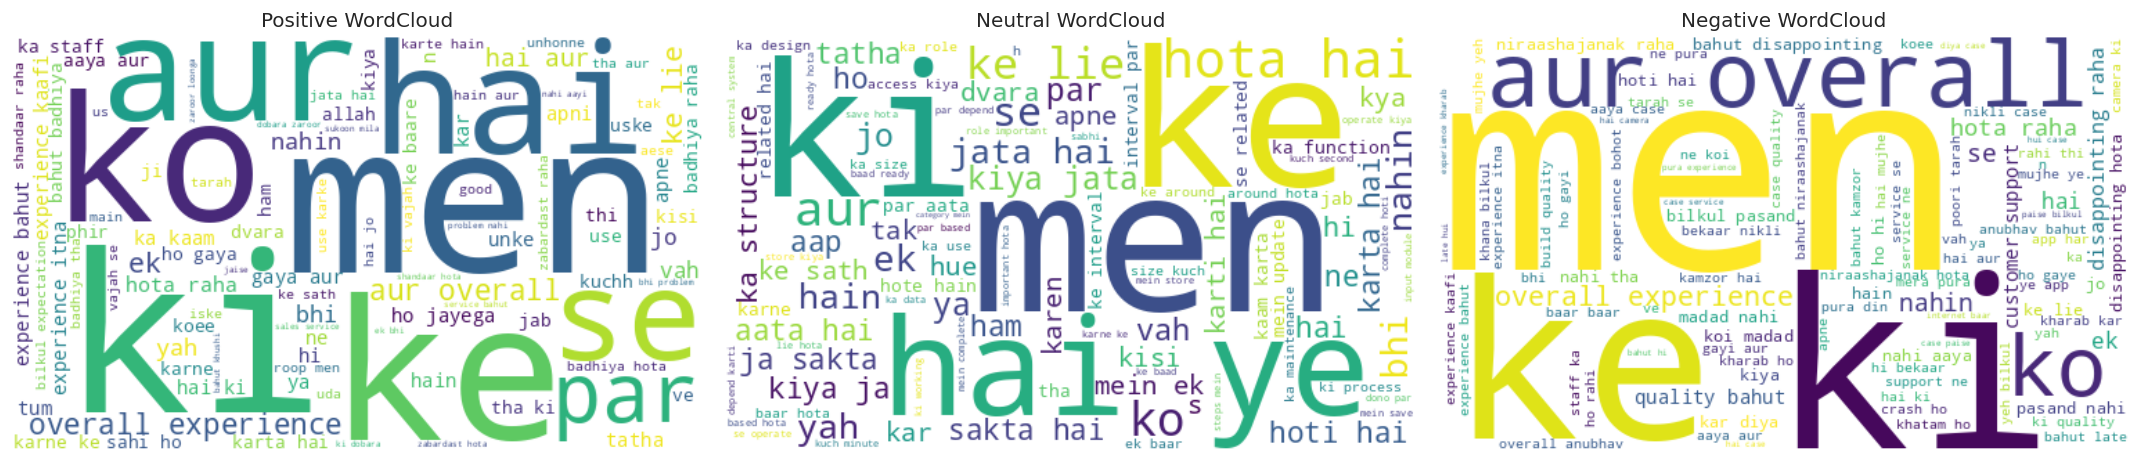

In [ ]:
# ── Word Clouds per sentiment ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, sentiment in zip(axes, order):
    text = ' '.join(df[df['sentiment'] == sentiment]['text'].dropna())
    wc = WordCloud(width=500, height=300, background_color='white',
                   max_words=100, colormap='viridis').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{sentiment.capitalize()} WordCloud')
    ax.axis('off')
plt.tight_layout()
plt.savefig('wordclouds.png')
plt.show()

## 3. Preprocessing Pipeline

In [ ]:
# ── English + common Hinglish stop-words ─────────────────────────────────────
ENGLISH_STOPS = set(stopwords.words('english'))

HINGLISH_STOPS = {
    'hai', 'hain', 'ho', 'ka', 'ki', 'ke', 'ko', 'se', 'me', 'mein',
    'ne', 'par', 'bhi', 'to', 'aur', 'yeh', 'woh', 'kya',
    'tha', 'the', 'thi', 'ek', 'un', 'unke', 'unki', 'unka', 'jo', 'jab',
    'jaise', 'phir', 'toh', 'lekin', 'aap', 'hum', 'main', 'mujhe',
    'tumhe', 've', 'voh', 'yahan', 'wahan', 'ab', 'tab', 'agar',
}
ALL_STOPS = ENGLISH_STOPS | HINGLISH_STOPS

def clean_text(text: str) -> str:
    """Clean a single Hinglish text sample."""
    if not isinstance(text, str):
        return ''
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove numbers (keep Devanagari numerals too)
    text = re.sub(r'[0-9]+', '', text)
    # Remove punctuation & special characters (keep alphanumeric + spaces)
    text = re.sub(r'[^\w\s]', ' ', text)
    # Remove extra whitespace and newlines
    text = re.sub(r'\s+', ' ', text).strip()
    # Tokenise → remove stops → rejoin
    tokens = text.split()
    tokens = [t for t in tokens if t not in ALL_STOPS and len(t) > 1]
    return ' '.join(tokens)

# Apply
df['clean_text'] = df['text'].apply(clean_text)

# Drop rows where clean_text is empty after cleaning
before = len(df)
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
print(f'Rows dropped (empty after cleaning): {before - len(df)}')
print(f'Final shape: {df.shape}')
df[['text', 'clean_text', 'sentiment', 'label']].head(5)

Rows dropped (empty after cleaning): 0
Final shape: (5706, 6)


,text,clean_text,sentiment,label
0,"module , ek program hoti hai , jismen ya to so...",module program hoti jismen ya source code ya m...,neutral,1
1,aur hamne aume samood ke pas unke bhaee saleh ...,hamne aume samood pas bhaee saleh paimbar bana...,positive,2
2,"aur jab unhen yad dilaya jata hai , to ve yad ...",unhen yad dilaya jata yad nahin karte,neutral,1
3,tumhen २०११ ka ted prize mil gaya hai\n,tumhen २०११ ted prize mil gaya,positive,2
4,unhonne bad science karne ke lie ye delhi univ...,unhonne bad science karne lie ye delhi univers...,neutral,1


In [ ]:
df['text'].duplicated().sum()

np.int64(0)

In [ ]:
# ── Average word count before vs after cleaning ───────────────────────────────
df['clean_word_count'] = df['clean_text'].str.split().str.len()
print('Avg word count RAW:    ', df['word_count'].mean().round(2))
print('Avg word count CLEAN:  ', df['clean_word_count'].mean().round(2))

Avg word count RAW:     14.34
Avg word count CLEAN:   10.17


In [ ]:
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

label
1    2095
0    1817
2    1794
Name: count, dtype: int64
label
1    36.715738
0    31.843673
2    31.440589
Name: proportion, dtype: float64


In [ ]:
# ── Casual-spelling normalization map (texting slang -> standard form) ───────
NORMALIZE_MAP = {
    'gya': 'gaya', 'gyi': 'gayi', 'hogya': 'hua', 'hun': 'hoon',
    'ma': 'main', 'mai': 'main', 'mjhe': 'mujhe', 'kr': 'kar',
    'krna': 'karna', 'krta': 'karta', 'krte': 'karte', 'kyu': 'kyun',
    'tujhe': 'tumhe', 'bohot': 'bahut', 'bht': 'bahut', 'h': 'hai',
    'nai': 'nahin', 'nhi': 'nahin', 'pora': 'pura', 'skta': 'sakta',
    'skte': 'sakte', 'thik': 'theek', 'tk': 'theek', 'acha': 'accha',
    'abi': 'abhi', 'kyuki': 'kyunki',
}

def clean_text(text: str) -> str:
    """Clean a single Hinglish text sample."""
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[0-9]+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    # Normalize casual spellings to standard form BEFORE stopword removal
    tokens = [NORMALIZE_MAP.get(t, t) for t in tokens]
    tokens = [t for t in tokens if t not in ALL_STOPS and len(t) > 1]
    return ' '.join(tokens)

## 4. Train / Val / Test Split

In [ ]:
# ── Stratified 70 / 15 / 15 split ────────────────────────────────────────────
X = df['clean_text']
y = df['label']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f'Train : {len(X_train):,} samples')
print(f'Val   : {len(X_val):,} samples')
print(f'Test  : {len(X_test):,} samples')

# Verify stratification
for split_name, y_split in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    counts = y_split.value_counts(normalize=True).round(3)
    print(f'  {split_name}: {counts.to_dict()}')

Train : 3,994 samples
Val   : 856 samples
Test  : 856 samples
  Train: {1: 0.367, 0: 0.318, 2: 0.314}
  Val: {1: 0.368, 0: 0.318, 2: 0.314}
  Test: {1: 0.367, 0: 0.319, 2: 0.314}


In [ ]:

import os
os.makedirs('/content/drive/MyDrive/data', exist_ok=True)

train_df.to_csv('/content/drive/MyDrive/data/train.csv', index=False)

# Create val_df and test_df
train_df = pd.DataFrame({'text': X_train, 'label': y_train})
val_df = pd.DataFrame({'text': X_val, 'label': y_val})
test_df = pd.DataFrame({'text': X_test, 'label': y_test})

train_df.to_csv('/content/drive/MyDrive/data/train.csv', index=False)
val_df.to_csv('/content/drive/MyDrive/data/val.csv', index=False)
test_df.to_csv('/content/drive/MyDrive/data/test.csv', index=False)

df[['clean_text', 'sentiment', 'label']].to_csv(
    '/content/drive/MyDrive/data/hinglish_clean.csv',
    index=False
)

print("Saved to Google Drive")

NameError: name 'train_df' is not defined

In [ ]:
train_check_df = pd.read_csv("/content/drive/MyDrive/data/train.csv")

print("Train set label counts:")
print(train_check_df['label'].value_counts())

print("\nFull dataset label counts (for comparison):")
print(df['label'].value_counts())

print("\nTrain set (y_train) label proportions:")
print(y_train.value_counts())

## 5. Summary
| Item | Detail |
|------|--------|
| Dataset | Hinglish Mendeley (2766 rows) |
| Label mapping | 0 = negative · 1 = neutral · 2 = positive |
| Class balance | ~44% neutral, ~36% positive, ~20% negative |
| Split | 70/15/15 stratified |
| Cleaning steps | lowercase, URL/HTML removal, punctuation, stop-words (EN + HI) |

➡ Proceed to **Notebook 2** for traditional ML models.